# Do the visual labels predict the choice?

Notebook 4 found that blacker fur lines up with a lower cat strength. Pose, eyes, and breed do not. This notebook asks whether those labels help the prediction itself: given the two photos, does the label gap change the probability of choosing A.

The feature on a row is photo A minus photo B. Fur colour shares are the pixel shares inside each cat. Pose, eyes, and breed are the one-hot label on A minus the one-hot label on B, with one level left out so the columns are not a copy of each other. The side column is a 1, as in the strength model.

The score is log loss on five pair folds. Both orders of a pair stay in one fold. Seed 21. `C = 1`. The between-cat side-only and cat-strength numbers match notebook 3.

In [1]:
import logging
from pathlib import Path

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

ROOT = Path.cwd()
if not (ROOT / "prepared" / "cleaned_training_responses.csv").exists():
    ROOT = ROOT.parent

FIG_DIR = ROOT / "model-checks" / "figures"
OUT_DIR = ROOT / "model-checks"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 21
N_FOLDS = 5
N_CAT_REPEATS = 5
C = 1.0

train = pd.read_csv(ROOT / "prepared" / "cleaned_training_responses.csv")
photos = pd.read_csv(ROOT / "prepared" / "photo_labels.csv").set_index("image")
between = train[train["comparison_type"].eq("between_cats")].reset_index(drop=True)
within = train[train["comparison_type"].eq("within_cat")].reset_index(drop=True)
print(f"between {len(between):,}   within {len(within):,}")

between 21,893   within 3,003


In [2]:
def logistic(x):
    return 1 / (1 + np.exp(-np.clip(x, -30, 30)))


def log_loss(y, p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    y = np.asarray(y, dtype=float)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def brier(y, p):
    y = np.asarray(y, dtype=float)
    p = np.asarray(p, dtype=float)
    return float(np.mean((p - y) ** 2))


def accuracy(y, p):
    y = np.asarray(y, dtype=float)
    return float(np.mean((np.asarray(p) >= 0.5) == (y == 1)))


def pair_masks(df, k, generator):
    pairs = generator.permutation(df["unordered_pair_id"].drop_duplicates().to_numpy())
    return [df["unordered_pair_id"].isin(set(fold)).to_numpy() for fold in np.array_split(pairs, k)]


def fit_strength(df):
    ids = pd.unique(np.concatenate([df["a_cat"].to_numpy(), df["b_cat"].to_numpy()]))
    index = {item: k for k, item in enumerate(ids)}
    n = len(df)
    X = np.zeros((n, len(ids) + 1))
    rows = np.arange(n)
    a = df["a_cat"].map(index).to_numpy()
    b = df["b_cat"].map(index).to_numpy()
    X[rows, a] += 1
    X[rows, b] -= 1
    X[:, -1] = 1
    clf = LogisticRegression(C=C, fit_intercept=False, solver="lbfgs", max_iter=500)
    clf.fit(X, df["chose_a"].to_numpy())
    coef = clf.coef_.ravel()
    strength = coef[:-1] - coef[:-1].mean()
    return {"strength": dict(zip(ids, strength)), "delta": float(coef[-1]), "ids": ids, "index": index}


def predict_strength(model, df):
    sa = df["a_cat"].map(model["strength"]).fillna(0).to_numpy(dtype=float)
    sb = df["b_cat"].map(model["strength"]).fillna(0).to_numpy(dtype=float)
    return logistic(sa - sb + model["delta"])


def positive_class(clf):
    return list(clf.classes_).index(1)


def score_features(df, X, masks):
    y = df["chose_a"].to_numpy()
    probability = np.empty(len(df))
    baseline = np.empty(len(df))
    coefs = []
    for mask in masks:
        clf = LogisticRegression(C=C, fit_intercept=False, solver="lbfgs", max_iter=800)
        clf.fit(X[~mask], y[~mask])
        probability[mask] = clf.predict_proba(X[mask])[:, positive_class(clf)]
        baseline[mask] = y[~mask].mean()
        coefs.append(clf.coef_.ravel())
    return probability, baseline, np.mean(coefs, axis=0)


def cat_plus_features(df, extra, masks):
    y = df["chose_a"].to_numpy()
    probability = np.empty(len(df))
    for mask in masks:
        fit_df = df.loc[~mask]
        model = fit_strength(fit_df)
        ids, index = model["ids"], model["index"]
        k = extra.shape[1]

        def design(part, block):
            n = len(part)
            X = np.zeros((n, len(ids) + k + 1))
            rows = np.arange(n)
            aa = part["a_cat"].map(index)
            bb = part["b_cat"].map(index)
            known_a = aa.notna().to_numpy()
            known_b = bb.notna().to_numpy()
            X[rows[known_a], aa[known_a].astype(int)] += 1
            X[rows[known_b], bb[known_b].astype(int)] -= 1
            X[:, len(ids) : len(ids) + k] = block
            X[:, -1] = 1
            return X

        clf = LogisticRegression(C=C, fit_intercept=False, solver="lbfgs", max_iter=800)
        clf.fit(design(fit_df, extra[~mask]), fit_df["chose_a"].to_numpy())
        probability[mask] = clf.predict_proba(design(df.loc[mask], extra[mask]))[:, positive_class(clf)]
    return probability


def numeric_diff(df, columns):
    left = photos.reindex(df["a_image"]).reset_index(drop=True)
    right = photos.reindex(df["b_image"]).reset_index(drop=True)
    parts = [(left[column] - right[column]).to_numpy(dtype=float) for column in columns]
    return np.nan_to_num(np.column_stack(parts))


def one_hot_diff(df, column):
    left = photos.reindex(df["a_image"])[column].fillna("").reset_index(drop=True)
    right = photos.reindex(df["b_image"])[column].fillna("").reset_index(drop=True)
    levels = sorted(set(left) | set(right))
    use = levels[:-1]
    parts = [(left.eq(level).astype(float) - right.eq(level).astype(float)).to_numpy() for level in use]
    return np.column_stack(parts) if parts else np.zeros((len(df), 0))


def with_side(block):
    return np.column_stack([block, np.ones(len(block))])


def metrics(name, y, probability, baseline):
    loss = log_loss(y, probability)
    base = log_loss(y, baseline)
    return {
        "model": name,
        "log_loss": loss,
        "brier": brier(y, probability),
        "accuracy": accuracy(y, probability),
        "gain_vs_side": base - loss,
    }

## Between cats

`share_white` is left out of the fur-colour block. The five shares that remain are the contrast with white, and their differences no longer sum to zero. The black-share row is that one column on its own.

,log_loss,brier,accuracy,gain_vs_side
model,,,,
side only,0.6924,0.2496,0.5197,0.0000
black share + side,0.6832,0.2451,0.5533,0.0092
fur colour shares + side,0.6813,0.2441,0.5582,0.0111
fur colour labels + side,0.6834,0.2452,0.5515,0.0090
pose and eyes + side,0.6905,0.2487,0.5256,0.0019
breed + side,0.6906,0.2487,0.5251,0.0018
shot size + side,0.6921,0.2495,0.5175,0.0003
cat strength + side,0.6552,0.2316,0.6075,0.0372
cat strength + black share,0.6550,0.2315,0.6091,0.0374


black-share coefficient, mean of the five fits: -0.799
sd of black share on A minus B: 0.344
log-odds for a one-sd gap: -0.275


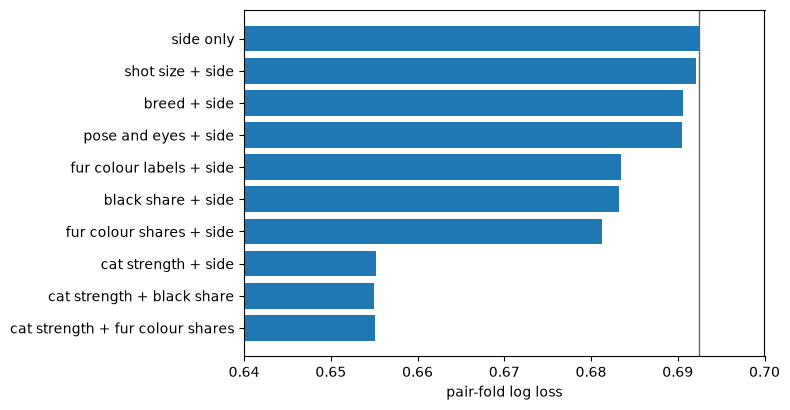

In [3]:
between_masks = pair_masks(between, N_FOLDS, np.random.default_rng(SEED))
y = between["chose_a"].to_numpy()

black = numeric_diff(between, ["share_black"])
coat = numeric_diff(between, ["share_black", "share_gray", "share_orange", "share_cream", "share_brown"])
coat_labels = np.column_stack([one_hot_diff(between, column) for column in ("colour_primary", "colour_pattern")])
pose = np.column_stack([one_hot_diff(between, column) for column in ("framing", "view", "eyes", "eyes_colour")])
breed = one_hot_diff(between, "breed")
area = numeric_diff(between, ["bbox_area_frac"])

cat_probability = np.empty(len(between))
side_probability = np.empty(len(between))
for mask in between_masks:
    fit_df = between.loc[~mask]
    cat_probability[mask] = predict_strength(fit_strength(fit_df), between.loc[mask])
    side_probability[mask] = fit_df["chose_a"].mean()

rows = [metrics("side only", y, side_probability, side_probability)]
feature_blocks = [
    ("black share + side", black),
    ("fur colour shares + side", coat),
    ("fur colour labels + side", coat_labels),
    ("pose and eyes + side", pose),
    ("breed + side", breed),
    ("shot size + side", area),
]
for name, block in feature_blocks:
    probability, _, _ = score_features(between, with_side(block), between_masks)
    rows.append(metrics(name, y, probability, side_probability))
rows.append(metrics("cat strength + side", y, cat_probability, side_probability))

black_on_cat = cat_plus_features(between, black, between_masks)
coat_on_cat = cat_plus_features(between, coat, between_masks)
rows.append(metrics("cat strength + black share", y, black_on_cat, side_probability))
rows.append(metrics("cat strength + fur colour shares", y, coat_on_cat, side_probability))

pair_scores = pd.DataFrame(rows).set_index("model")
pair_scores.to_csv(OUT_DIR / "label_pair_holdout.csv")
display(pair_scores.round(4))

_, _, black_coef = score_features(between, with_side(black), between_masks)
gap = black[:, 0]
print(f"black-share coefficient, mean of the five fits: {black_coef[0]:.3f}")
print(f"sd of black share on A minus B: {gap.std(ddof=1):.3f}")
print(f"log-odds for a one-sd gap: {black_coef[0] * gap.std(ddof=1):.3f}")

plot_order = [
    "side only",
    "shot size + side",
    "breed + side",
    "pose and eyes + side",
    "fur colour labels + side",
    "black share + side",
    "fur colour shares + side",
    "cat strength + side",
    "cat strength + black share",
    "cat strength + fur colour shares",
]
shown = pair_scores.loc[plot_order]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(shown.index[::-1], shown["log_loss"].to_numpy()[::-1], color="C0")
ax.axvline(pair_scores.loc["side only", "log_loss"], color="0.4", lw=1)
ax.set_xlabel("pair-fold log loss")
ax.set_xlim(0.64, 0.70)
fig.tight_layout()
fig.savefig(FIG_DIR / "label_pair_holdout.png", bbox_inches="tight")
plt.show()

## Cats the fit has not seen

The pair folds mostly score cats that were in the fit. Fur colour can still matter when a cat was held out, because a new cat has strength 0. A quarter of the cats are removed, and a fifth of the remaining pairs are held out. Five repeats, seed 21.

,n,side,fur colour shares,cat strength
slice,,,,
"both seen, new pair",2427.2,0.6922,0.6803,0.6575
one unseen cat,8254.4,0.6925,0.6831,0.6848
two unseen cats,1342.8,0.6924,0.6794,0.6924


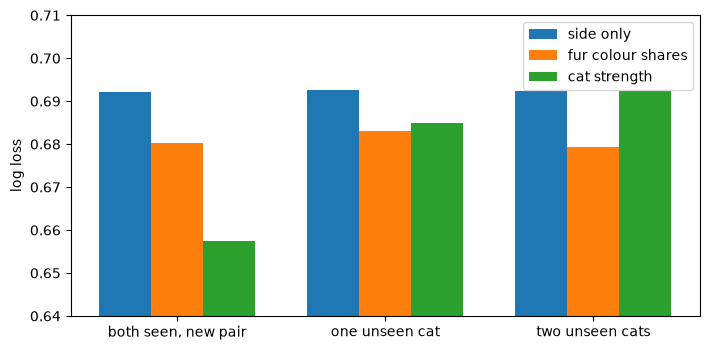

In [4]:
hold_rows = []
hold_rng = np.random.default_rng(SEED)
coat_design = with_side(coat)
for repeat in range(N_CAT_REPEATS):
    cats = np.unique(np.concatenate([between["a_cat"].to_numpy(), between["b_cat"].to_numpy()]))
    held_cats = set(hold_rng.permutation(cats)[: len(cats) // 4])
    seen_pair = ~between["a_cat"].isin(held_cats) & ~between["b_cat"].isin(held_cats)
    seen_ids = between.loc[seen_pair, "unordered_pair_id"].drop_duplicates().to_numpy()
    n_hold = max(1, int(round(len(seen_ids) * 0.2)))
    held_pairs = set(hold_rng.permutation(seen_ids)[:n_hold])
    fit_mask = (seen_pair & ~between["unordered_pair_id"].isin(held_pairs)).to_numpy()
    n_unseen = between["a_cat"].isin(held_cats).astype(int) + between["b_cat"].isin(held_cats).astype(int)
    slices = {
        "both seen, new pair": between["unordered_pair_id"].isin(held_pairs).to_numpy(),
        "one unseen cat": (n_unseen == 1).to_numpy(),
        "two unseen cats": (n_unseen == 2).to_numpy(),
    }
    fit_df = between.loc[fit_mask]
    cat_p = predict_strength(fit_strength(fit_df), between)
    clf = LogisticRegression(C=C, fit_intercept=False, solver="lbfgs", max_iter=500)
    clf.fit(coat_design[fit_mask], y[fit_mask])
    coat_p = clf.predict_proba(coat_design)[:, positive_class(clf)]
    side_p = np.full(len(between), y[fit_mask].mean())
    for name, mask in slices.items():
        hold_rows.append(
            {
                "repeat": repeat,
                "slice": name,
                "n": int(mask.sum()),
                "side": log_loss(y[mask], side_p[mask]),
                "fur colour shares": log_loss(y[mask], coat_p[mask]),
                "cat strength": log_loss(y[mask], cat_p[mask]),
            }
        )

hold = pd.DataFrame(hold_rows)
hold_summary = (
    hold.groupby("slice")[["n", "side", "fur colour shares", "cat strength"]]
    .mean()
    .reindex(["both seen, new pair", "one unseen cat", "two unseen cats"])
)
hold_summary.to_csv(OUT_DIR / "label_unseen_cat_holdout.csv")
display(hold_summary.round(4))

fig, ax = plt.subplots(figsize=(7.2, 3.6))
x = np.arange(len(hold_summary))
width = 0.25
for offset, column, label in (
    (-width, "side", "side only"),
    (0, "fur colour shares", "fur colour shares"),
    (width, "cat strength", "cat strength"),
):
    ax.bar(x + offset, hold_summary[column], width=width, label=label)
ax.set_xticks(x, hold_summary.index)
ax.set_ylabel("log loss")
ax.set_ylim(0.64, 0.71)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "label_unseen_cat_holdout.png", bbox_inches="tight")
plt.show()

## Within a cat

The two photos are the same cat, so the fur-colour label is almost the same object twice. What can differ is the shot: framing, view, eyes, and how much of the frame the cat fills. The side rate is the baseline notebook 3 keeps for these rows.

In [5]:
within_masks = pair_masks(within, N_FOLDS, np.random.default_rng(SEED))
yw = within["chose_a"].to_numpy()
within_side = np.empty(len(within))
for mask in within_masks:
    within_side[mask] = yw[~mask].mean()

within_rows = [metrics("side only", yw, within_side, within_side)]
within_blocks = [
    ("black share + side", numeric_diff(within, ["share_black"])),
    ("fur colour shares + side", numeric_diff(within, ["share_black", "share_gray", "share_orange", "share_cream", "share_brown"])),
    ("framing + side", one_hot_diff(within, "framing")),
    ("view + side", one_hot_diff(within, "view")),
    ("eyes + side", one_hot_diff(within, "eyes")),
    ("shot size + side", numeric_diff(within, ["bbox_area_frac"])),
]
for name, block in within_blocks:
    probability, _, _ = score_features(within, with_side(block), within_masks)
    within_rows.append(metrics(name, yw, probability, within_side))

within_scores = pd.DataFrame(within_rows).set_index("model")
within_scores.to_csv(OUT_DIR / "label_within_cat_holdout.csv")
display(within_scores.round(4))

,log_loss,brier,accuracy,gain_vs_side
model,,,,
side only,0.6938,0.2503,0.5142,0.0000
black share + side,0.6935,0.2502,0.5198,0.0003
fur colour shares + side,0.6961,0.2515,0.5115,-0.0023
framing + side,0.6936,0.2502,0.5171,0.0002
view + side,0.6940,0.2504,0.5225,-0.0002
eyes + side,0.6935,0.2502,0.5162,0.0003
shot size + side,0.6939,0.2504,0.5122,-0.0001


## What decides it

On between-cat pairs, fur colour shares lower the log loss from 0.6924 to 0.6813. Black share alone gets to 0.6832. Every fold moves the same way: the five gains run from 0.008 to 0.015. Pose and eyes gain 0.002, breed 0.002, and shot size 0.000. Cat strength reaches 0.6552.

A one-standard-deviation gap in black share is about −0.27 log-odds, from the coefficient −0.80. The side effect in notebook 3 is 0.088. The gap in cat strength has standard deviation 0.67. Fur colour is larger than the side tilt and smaller than which cat it is.

Adding the fur-colour columns to cat strength changes the pair-fold log loss by 0.0002. Once the fit knows the cat, the fur colour is already in the strength.

Fur colour is the part that still predicts a cat the fit has not seen. With both cats unseen, cat strength stays on the side rate and fur colour shares beat that rate by about 0.013. With one cat unseen, fur colour and cat strength land on about the same log loss.

Within a cat, none of these photo labels beat the side rate by a meaningful amount, and the fur-colour model is slightly worse. The labels stay out of the choice model.